# Week 2 - Exploratory Data Analysis and Visualization

This notebook walks through the analysis behind
`reports/Week2_EDA_and_Visualization.docx` using the same functions in `src/`.
Every number below is recomputed from `data/processed/shipments_clean.csv`;
the seed is fixed at 42 in `src/generate_data.py`.

Run `make week2` from the repository root to rebuild the data, figures,
results and report, then execute this notebook against them.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.analyze import (build_cost, build_correlations, build_descriptive,
                         build_lanes, build_outliers, build_profile,
                         build_tests)

DATA = ROOT / "data" / "processed" / "shipments_clean.csv"
REAL = ROOT / "data" / "external" / "bts_border_trucks.csv.gz"
FIG = ROOT / "figures"
RESULTS = ROOT / "results"

df = pd.read_csv(DATA, parse_dates=["order_date", "ship_date",
                                    "delivery_date", "month_start"])
real = pd.read_csv(REAL, parse_dates=["date"])
clean = json.loads((RESULTS / "cleaning.json").read_text())
prof = json.loads((RESULTS / "profile.json").read_text())
print(f"cleaned rows: {len(df):,}  columns: {df.shape[1]}")
print(f"window: {df['order_date'].min():%Y-%m-%d} to {df['order_date'].max():%Y-%m-%d}")
print(f"BTS rows: {len(real):,}  ports: {real['port_name'].nunique()}")

cleaned rows: 49,935  columns: 35
window: 2024-01-01 to 2025-12-31
BTS rows: 38,567  ports: 114


## 1. Profile and data quality

`build_profile` counts rows, flags and eligible denominators. Cost is missing
not at random, so it is never imputed and on-time rates use only shipments with
a terminal status.

In [2]:
profile = build_profile(df, (clean["rows_raw"], clean["cols_raw"]))
for key in ["rows_clean", "cols_clean", "on_time_eligible", "on_time_rate",
            "cost_scored_rows", "cost_missing_share", "lane_count"]:
    print(f"{key:20s} {profile[key]}")
print("\nstatus counts:", profile["status_counts"])

rows_clean           49935
cols_clean           35
on_time_eligible     48847
on_time_rate         0.8283
cost_scored_rows     47316
cost_missing_share   0.0524
lane_count           117

status counts: {'Delivered': 40459, 'Delayed': 8388, 'In Transit': 735, 'Cancelled': 353}


## 2. Distributions by mode

Transit is right-skewed with a second mass near 24 days, which is sea freight.
The mode comparison uses medians and 90th percentiles because the mean is
dragged by a tail that reaches 75 days.

In [3]:
desc = build_descriptive(df)
summary = pd.DataFrame({
    m: {"shipments": v["shipments"],
        "share": round(v["share"], 4),
        "median transit (d)": v["median_transit_days"],
        "p90 transit (d)": v["p90_transit_days"],
        "on-time": round(v["on_time_rate"], 4),
        "median cost/kg": round(v["median_cost_per_kg"], 2)}
    for m, v in desc["by_mode"].items()}).T
summary

,shipments,share,median transit (d),p90 transit (d),on-time,median cost/kg
Air,12574.0,0.2518,3.0,5.0,0.7921,46.19
Rail,4333.0,0.0868,9.0,12.0,0.9161,0.90
Road,14373.0,0.2878,6.0,9.0,0.7939,2.40
Sea,18655.0,0.3736,24.0,33.0,0.8587,5.98


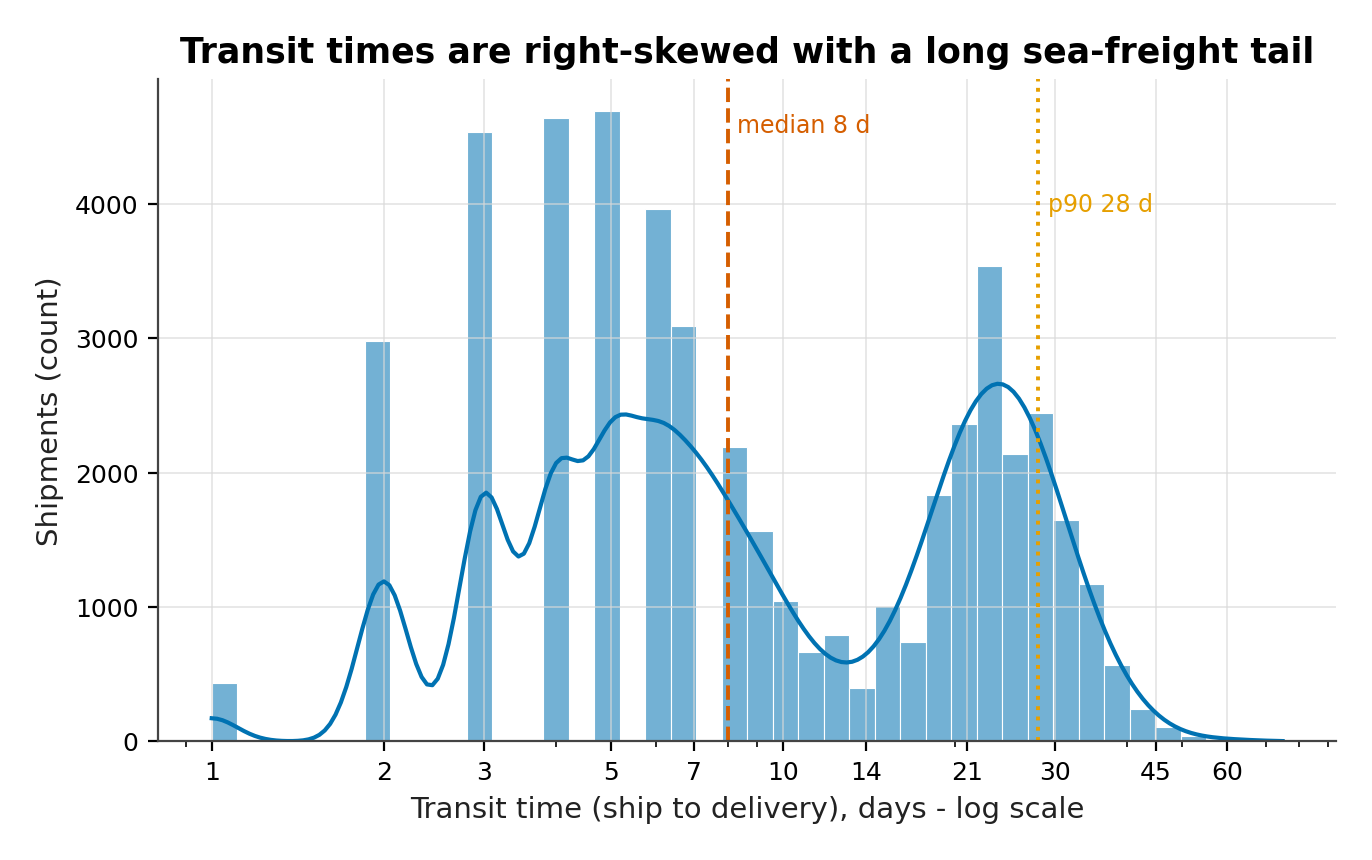

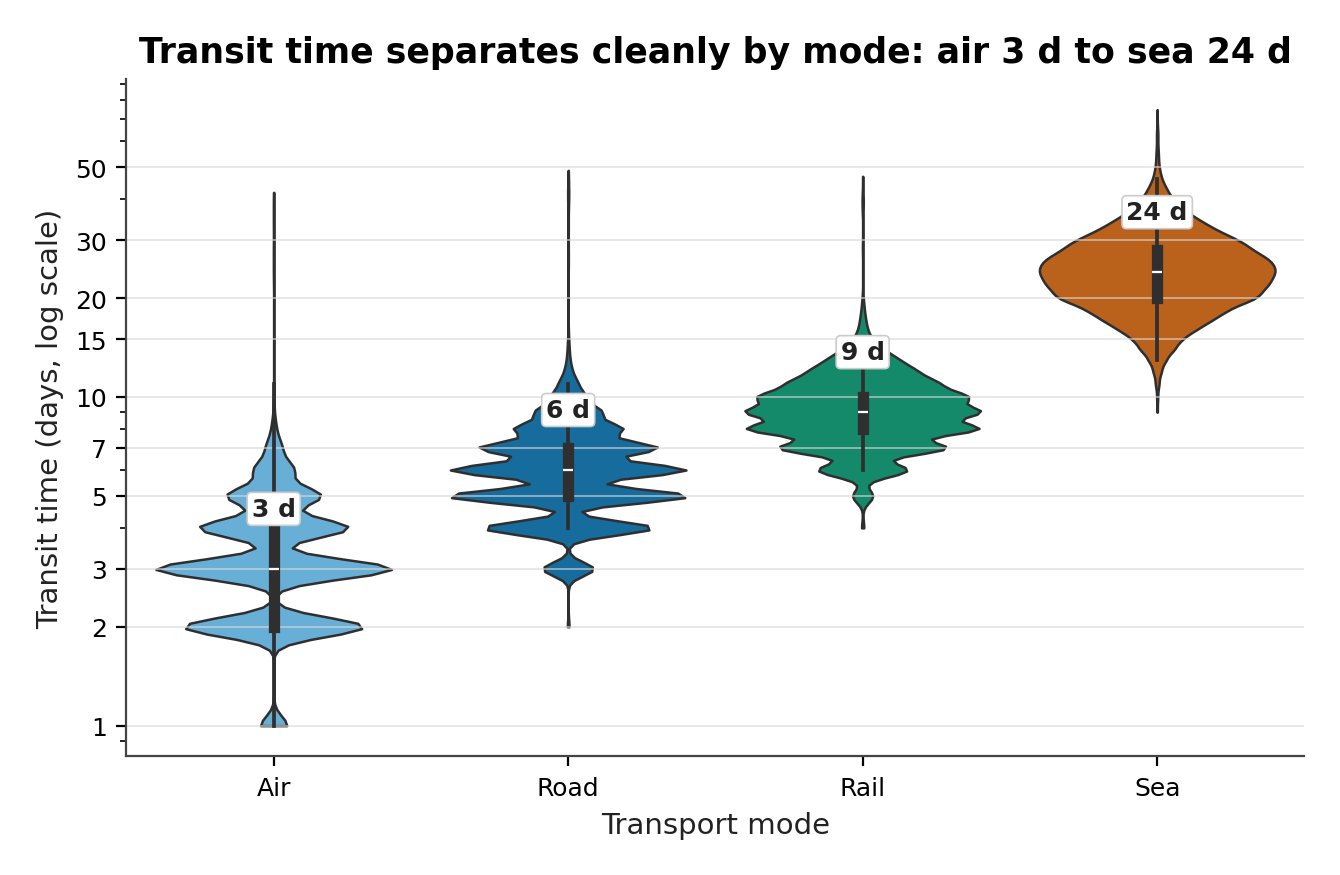

In [4]:
display(Image(filename=str(FIG / "fig02_transit_histogram.png"), width=760))
display(Image(filename=str(FIG / "fig03_mode_violin.png"), width=760))

## 3. Trend and seasonality

The fourth-quarter index compares the mean of October to December with the
other nine months. STL separates the calendar from the trend; the seasonal
strength is the share of variance the seasonal component explains.

In [5]:
ts = json.loads((RESULTS / "timeseries.json").read_text())
s, dec, dis = ts["summary"], ts["decomposition"], ts["disruption"]
print(f"mean monthly volume      {s['mean_monthly']:,.1f}")
print(f"peak / trough            {s['peak_month'][:7]} {s['peak_value']:,} | "
      f"{s['trough_month'][:7]} {s['trough_value']:,}")
print(f"Q4 index                 {s['q4_index']:.3f}  (+{s['q4_uplift_pct']:.1f}%)")
print(f"seasonal strength        {dec['seasonal_strength']:.3f}")
print(f"trend strength           {dec['trend_strength']:.3f}")
print(f"Feb 2025 on-time         {dis['feb_on_time']:.3f} vs {dis['baseline_on_time']:.3f}")

mean monthly volume      2,080.6
peak / trough            2024-11 2,680 | 2024-01 1,685
Q4 index                 1.348  (+34.8%)
seasonal strength        0.989
trend strength           0.016
Feb 2025 on-time         0.714 vs 0.831


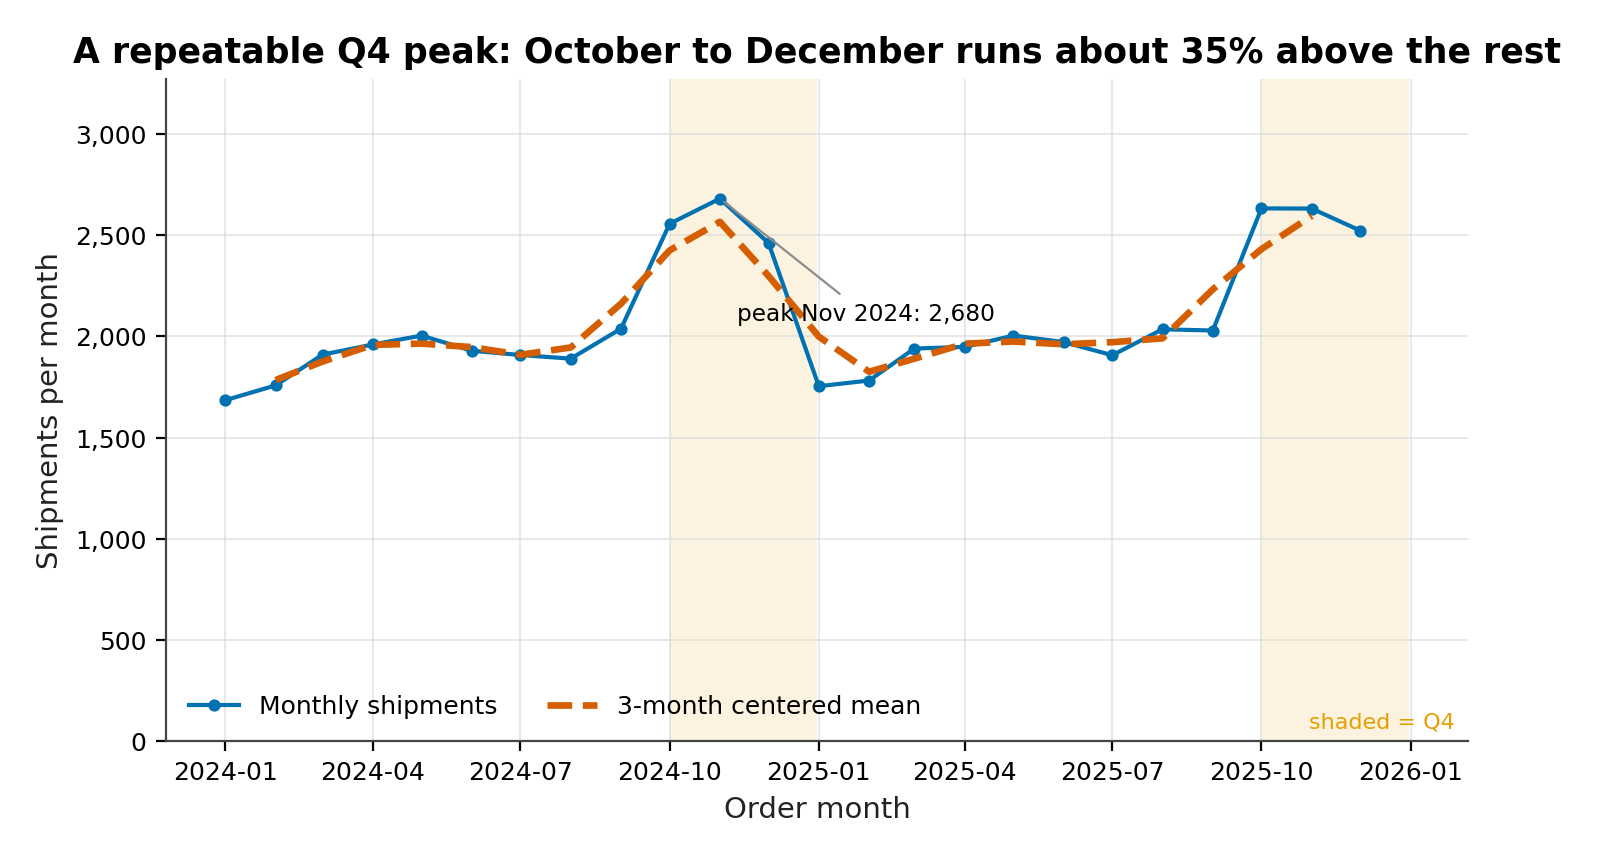

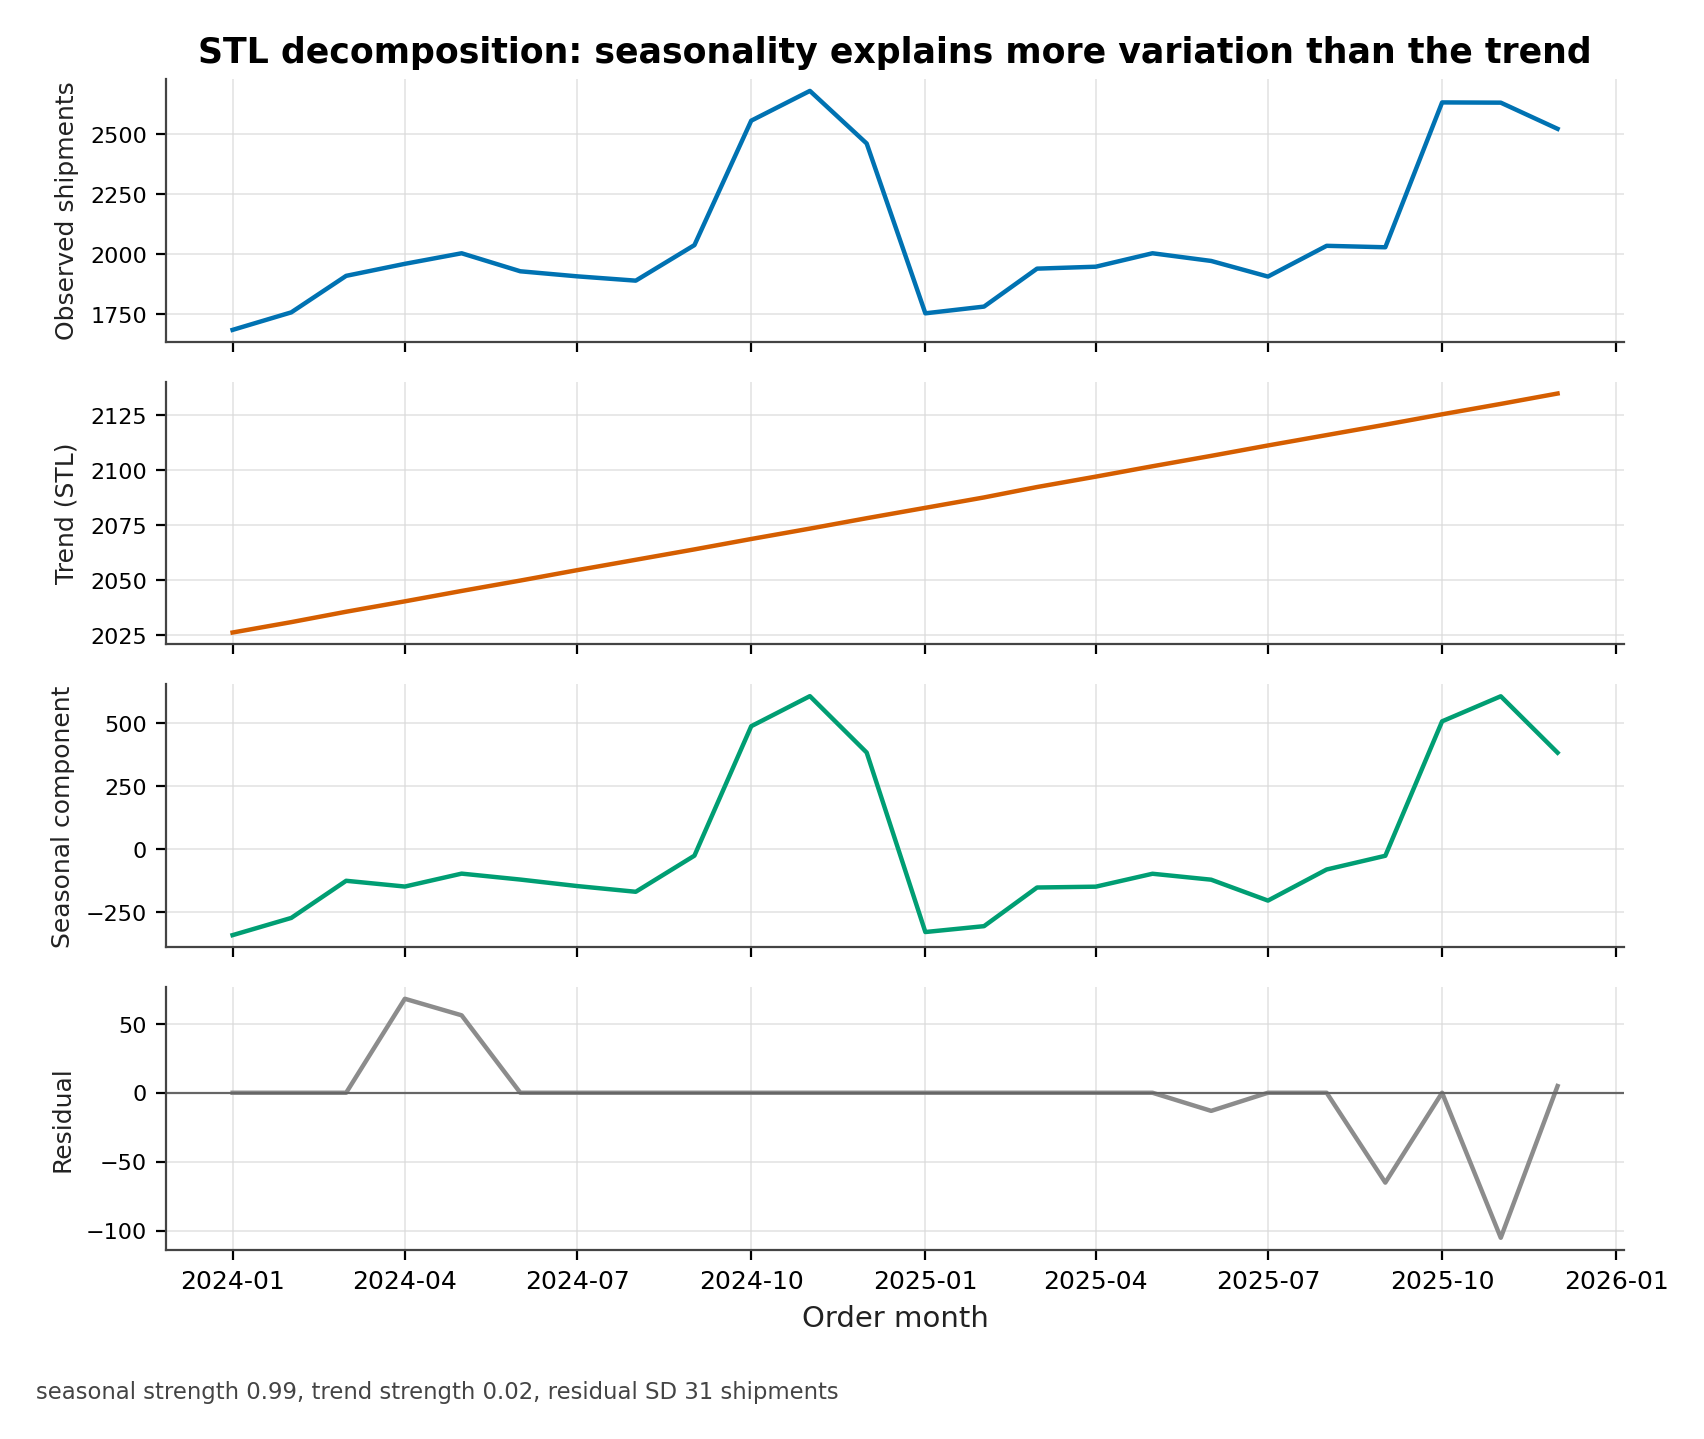

In [6]:
display(Image(filename=str(FIG / "fig04_monthly_volume.png"), width=760))
display(Image(filename=str(FIG / "fig05_stl_decomposition.png"), width=760))

## 4. Relationships and group tests

Pearson understates a multiplicative relationship, so the matrix is Spearman.
Group tests use Kruskal-Wallis with epsilon-squared, and carrier differences use
chi-square with Cramer's V because the sample is large enough to make p-values
uninformative on their own.

In [7]:
corr = build_correlations(df)
print(corr["top_pairs"][:3])
tests = build_tests(df)
print("\nmode transit: H =", round(tests["transit_by_mode"]["kruskal_h"], 2),
      "epsilon^2 =", tests["transit_by_mode"]["epsilon_squared"])
otc = tests["on_time_by_carrier"]
print(f"carrier on-time: chi2 {otc['chi2']:.2f}, V {otc['cramers_v']:.3f}, "
      f"{otc['best_carrier']} {otc['best_rate']:.3f} vs "
      f"{otc['worst_carrier']} {otc['worst_rate']:.3f}")

[{'pair': 'weight_kg / volume_m3', 'pearson': 0.916, 'spearman': 0.981}, {'pair': 'transit_days / promised_days', 'pearson': 0.9006, 'spearman': 0.9032}, {'pair': 'distance_km / freight_cost_usd', 'pearson': 0.3675, 'spearman': 0.7163}]



mode transit: H = 40707.22 epsilon^2 = 0.8334
carrier on-time: chi2 4023.43, V 0.287, Ironline Rail 0.907 vs Northwind Cargo 0.594


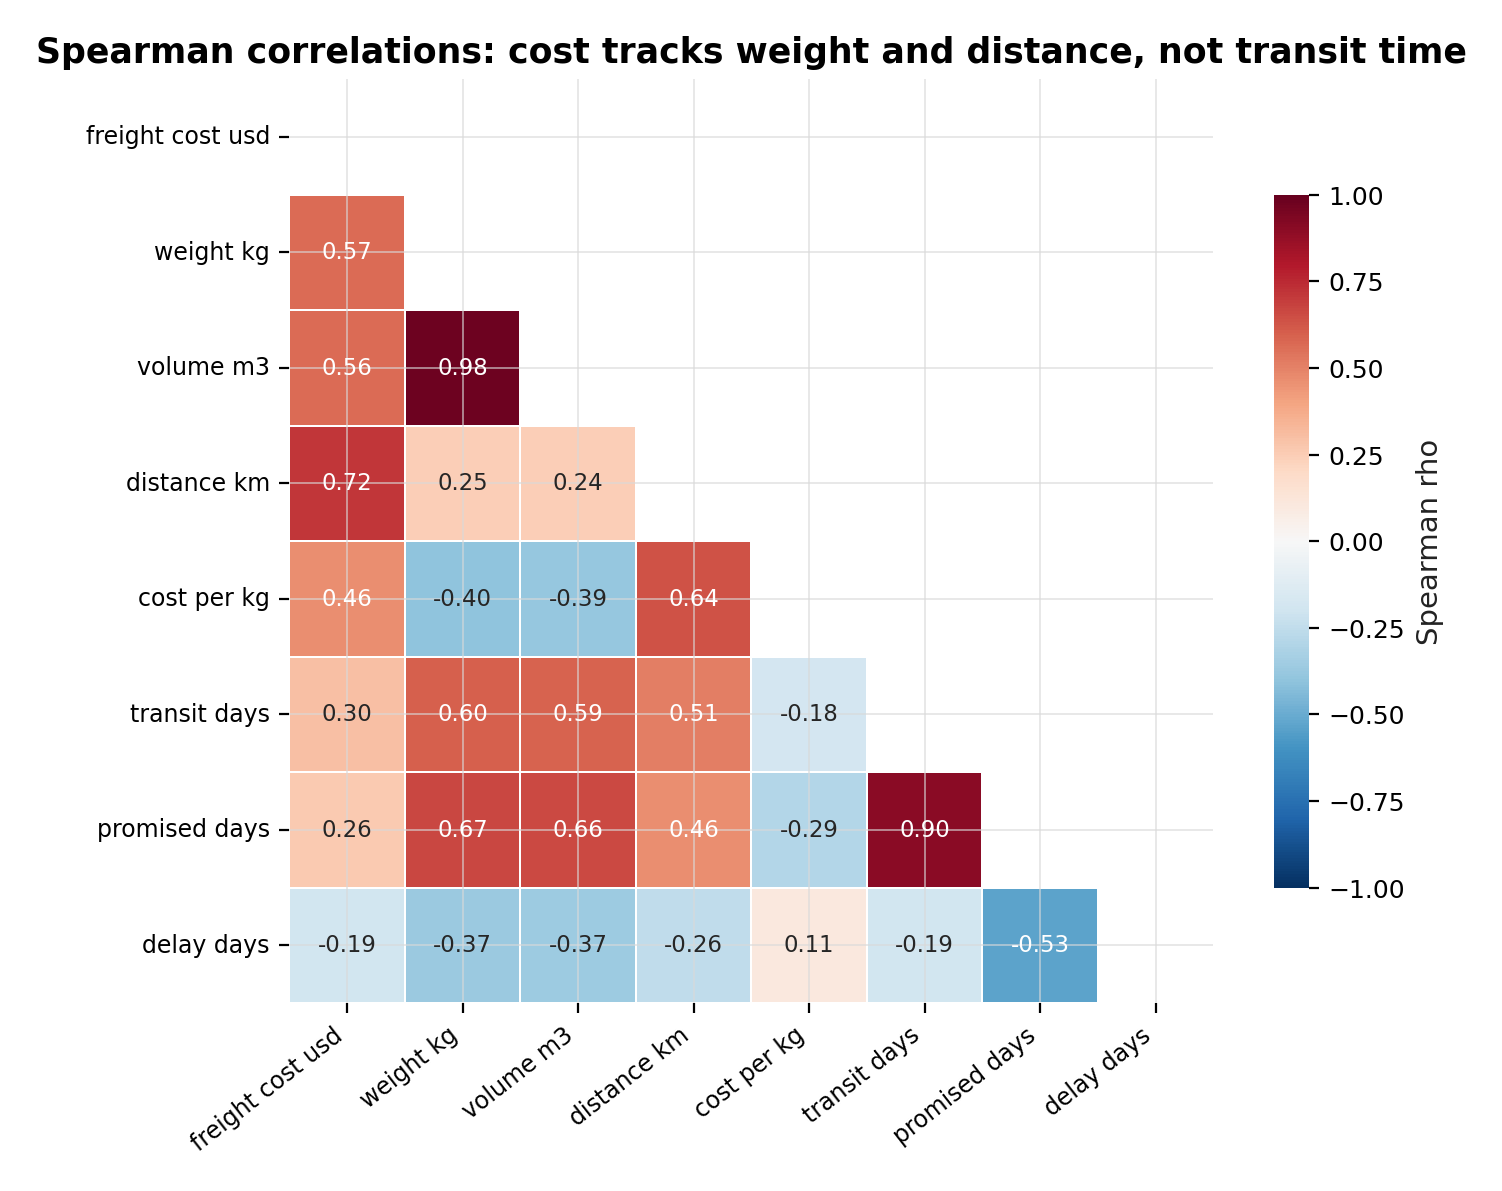

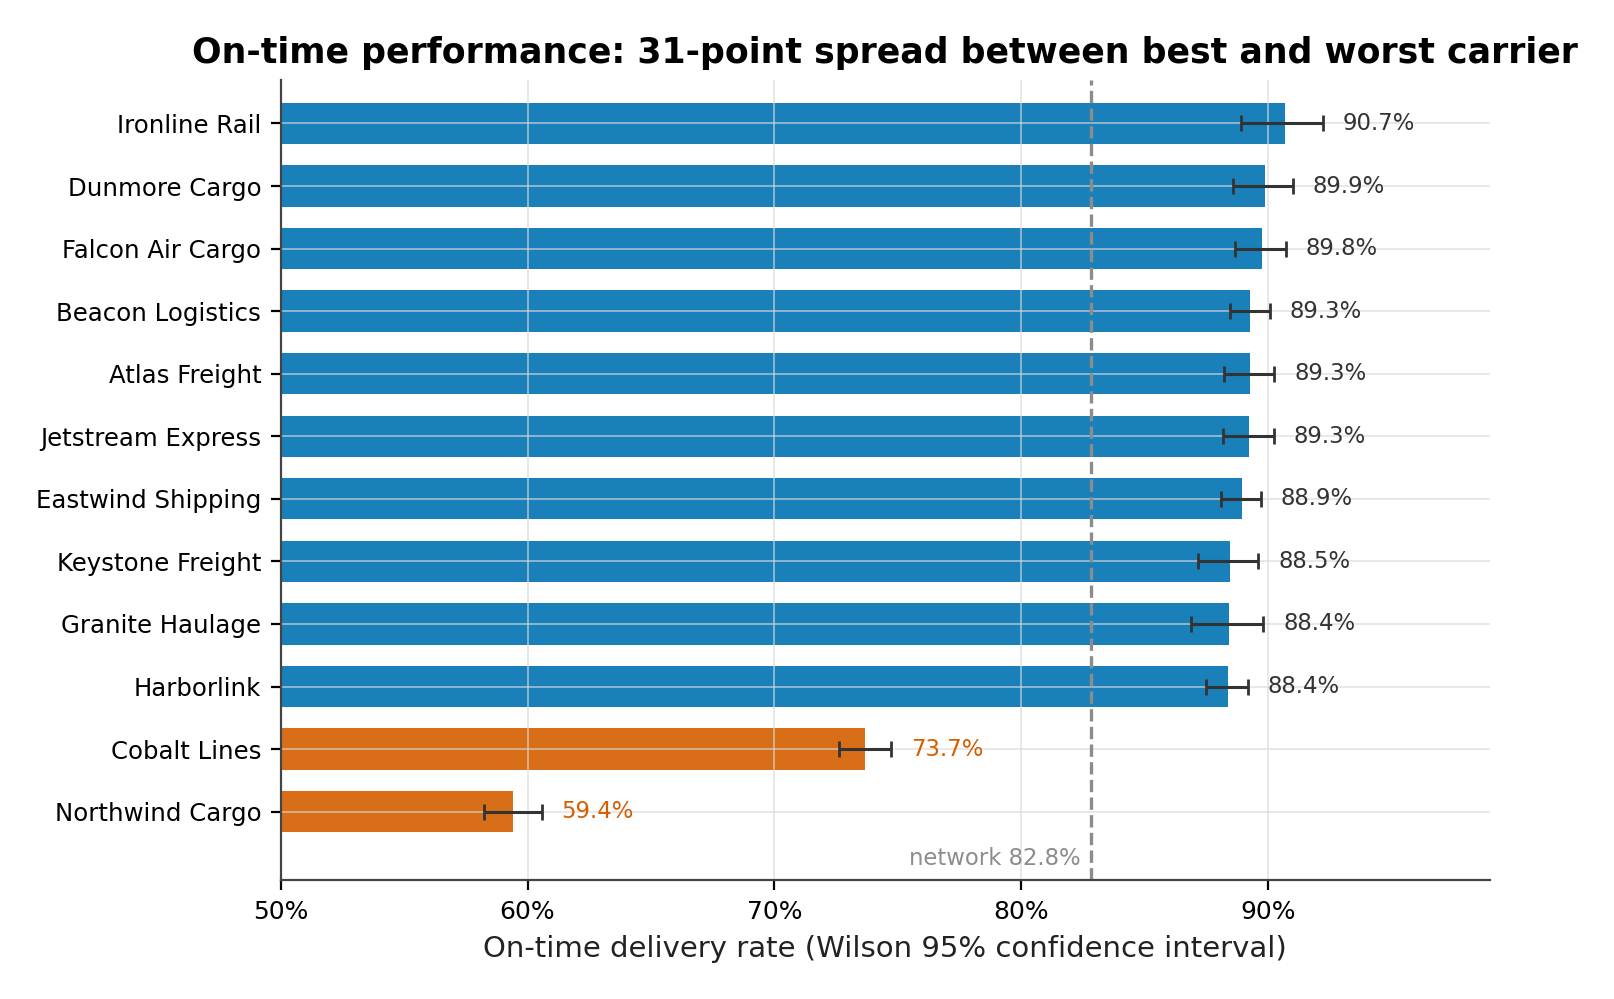

In [8]:
display(Image(filename=str(FIG / "fig06_correlation_heatmap.png"), width=700))
display(Image(filename=str(FIG / "fig07_carrier_ontime.png"), width=760))

## 5. Cost structure

The primary model regresses log cost on log weight, log distance and mode fixed
effects. The coefficients are elasticities, directly comparable with the
planted values of 0.82 and 1.00.

In [9]:
cost = build_cost(df)
m = cost["model"]
print(f"rows                 {m['n']:,}")
print(f"weight elasticity    {m['weight_elasticity']:.4f}  CI {m['weight_ci']}")
print(f"distance elasticity  {m['distance_elasticity']:.4f}  CI {m['distance_ci']}")
print(f"R2                   {m['r2']:.4f}")
print(f"pooled weight elast. {cost['pooled']['weight_elasticity']:.4f}")
print(f"air : sea cost/kg    {cost['air_to_sea_ratio']:.2f}x")

rows                 47,310
weight elasticity    0.8009  CI [0.7982, 0.8036]
distance elasticity  1.0011  CI [0.9952, 1.0069]
R2                   0.9537
pooled weight elast. 0.4740
air : sea cost/kg    7.70x


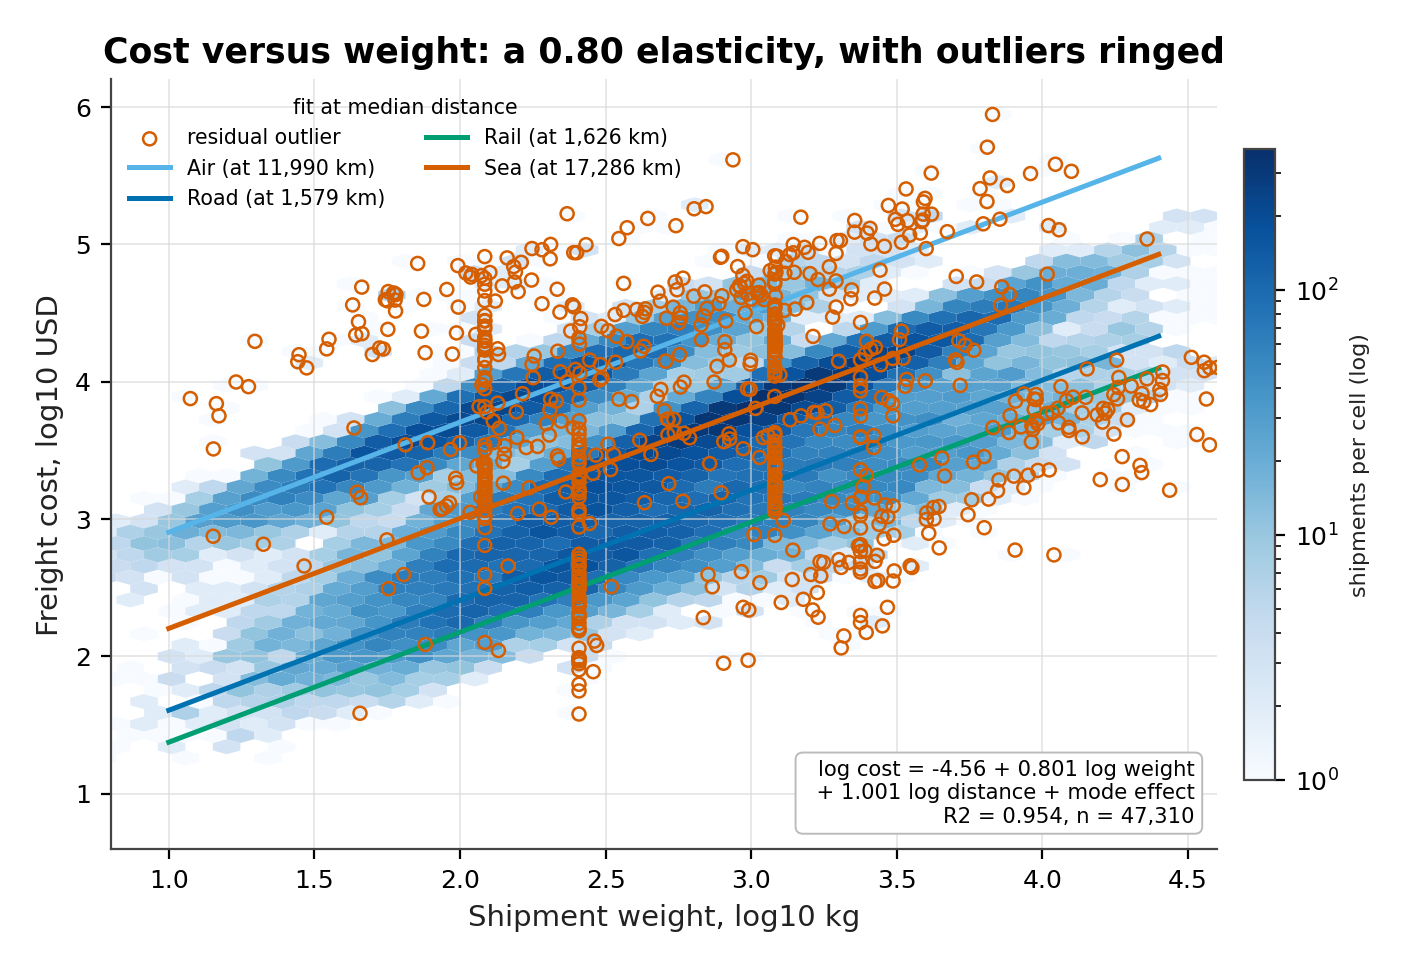

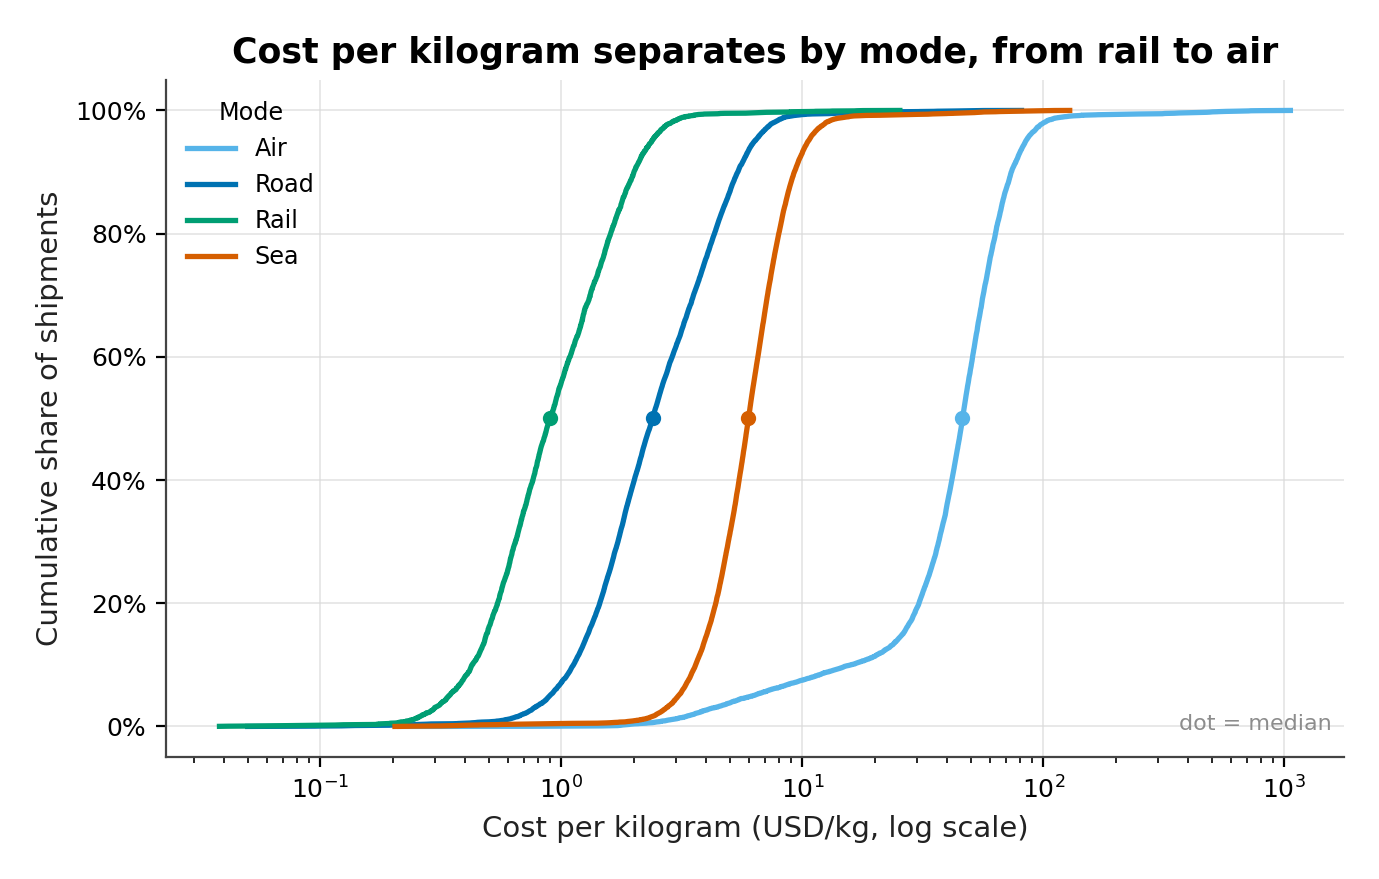

In [10]:
display(Image(filename=str(FIG / "fig08_cost_loglog.png"), width=760))
display(Image(filename=str(FIG / "fig12_cost_per_kg_ecdf.png"), width=760))

## 6. Outliers and network concentration

Four rules are scored against the planted anomalies. The residual rule wins
because corruption is conditional on weight, distance and mode; a univariate
fence cannot see that. Lane concentration uses a Herfindahl-Hirschman index.

In [11]:
out = build_outliers(df)
comp = pd.DataFrame(out["recovery"]["comparison"])[["method", "flagged", "recall", "precision"]]
display(comp.round(4))
print(f"planted rows {out['profile']['planted_rows']:,} "
      f"({out['profile']['planted_share']:.3f} of the file)")
lanes = build_lanes(df)
print(f"lanes {lanes['lane_count']}, top 10 {lanes['top10_share_pct']:.1f}%, "
      f"HHI {lanes['hhi']:.3f}, {lanes['lanes_for_80pct']} lanes for 80%")

,method,flagged,recall,precision
0,IQR fence,6644,0.5378,0.0557
1,z-score > 3,1263,0.3372,0.1837
2,modified z (raw),10036,0.6773,0.0464
3,residual-modified z,1176,0.9084,0.5315


planted rows 688 (0.014 of the file)
lanes 117, top 10 29.0%, HHI 0.016, 55 lanes for 80%


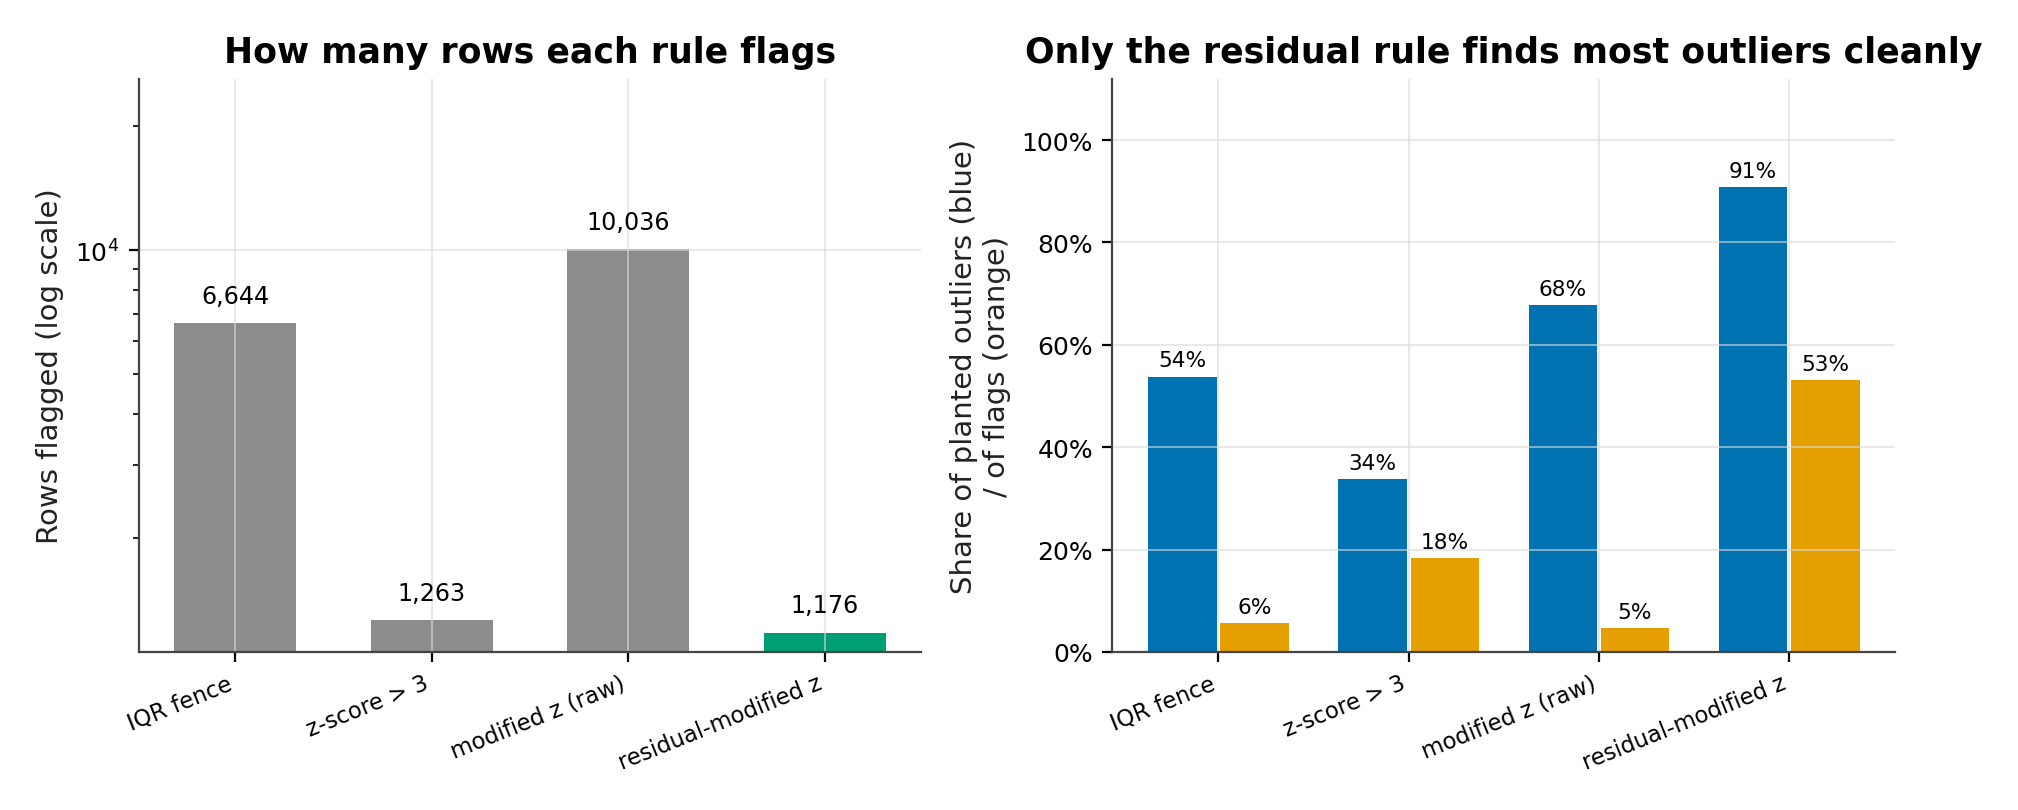

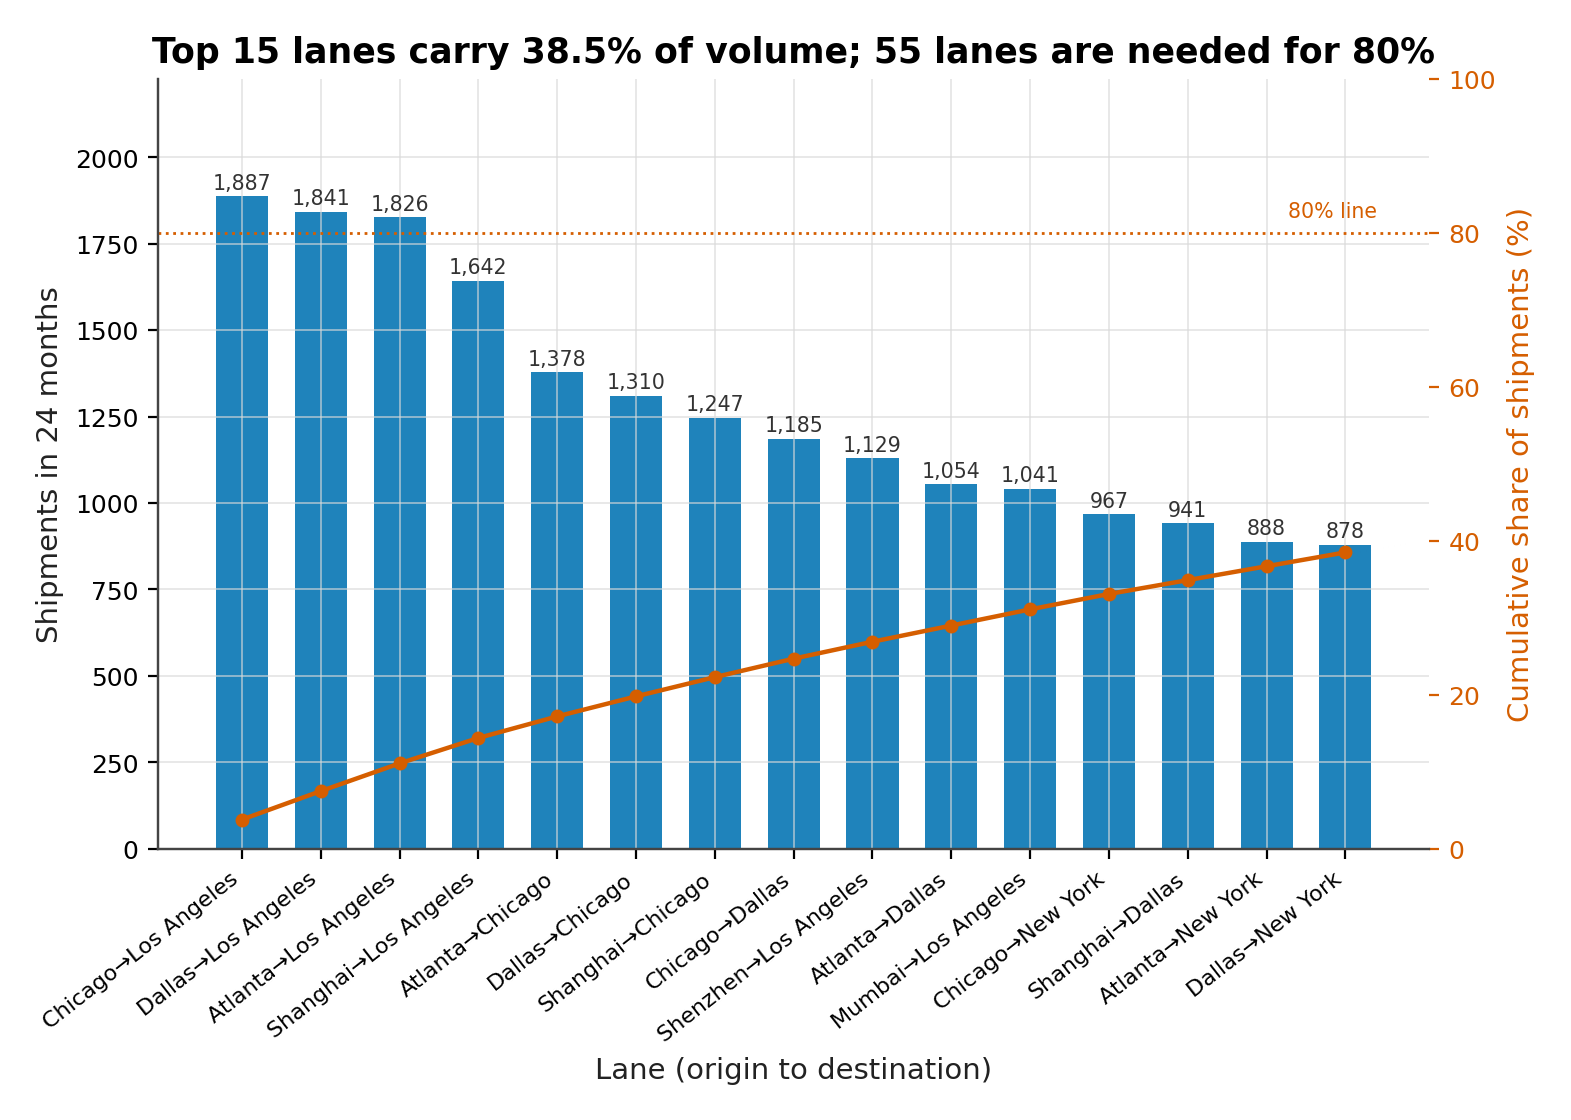

In [12]:
display(Image(filename=str(FIG / "fig09_outlier_methods.png"), width=700))
display(Image(filename=str(FIG / "fig11_lane_pareto.png"), width=760))

## 7. External benchmark and validation

The BTS series is an independent check on the seasonal story. Validation
compares each planted design value with the recovered estimate; ten of ten
pass, and the cost elasticity is the one deliberate near-miss.

In [13]:
real_ts = ts["real_data"]
print(f"BTS months           {len(real_ts['monthly']['values'])}")
print(f"December index       {real_ts['december_index']:.3f}")
print(f"October index        {real_ts['october_index']:.3f}")
print(f"2020 vs 2019         {real_ts['annual_2020_vs_2019_pct']:.1f}%")
val = json.loads((RESULTS / "validation.json").read_text())
display(pd.DataFrame(val["rows"])[["effect", "planted", "recovered", "match"]])

BTS months           201
December index       0.912
October index        1.057
2020 vs 2019         -4.5%


,effect,planted,recovered,match
0,Q4 volume peak,Q4 month weight 1.35x baseline,Q4 index 1.348 (34.8% above other months),True
1,Mode-specific transit times,"medians Air 3 d, Rail 9 d, Road 6 d, Sea 24 d","medians Air 3 d, Road 6 d, Rail 9 d, Sea 24 d",True
2,Two weak carriers,"Northwind Cargo 59.5%, Cobalt Lines 73.7%","Northwind Cargo 59.4%, Cobalt Lines 73.7%",True
3,February 2025 disruption,"2025-02, Sea +2.6 days","2.0 extra Sea days, on-time 71.4% vs 83.1%",True
4,Cost ~ weight^0.82,elasticity 0.82,0.801 (95% CI 0.798-0.804),True
5,Cost ~ distance^1.0,elasticity 1.00,1.001,True
6,Planted outliers,"1.4% of rows: cost x5-12, weight x8-20, transi...",residual-modified z flags 2.36% of rows and re...,True
7,Duplicate rows,600 rows,600 removed,True
8,Missing freight cost (MNAR),"5-8% for Air and Sea, 10% for the top cost decile",5.24% overall,True
9,Priority affects speed,"High priority 12% faster, Low 12% slower",median 7 d (High) vs 8 d (Low),True


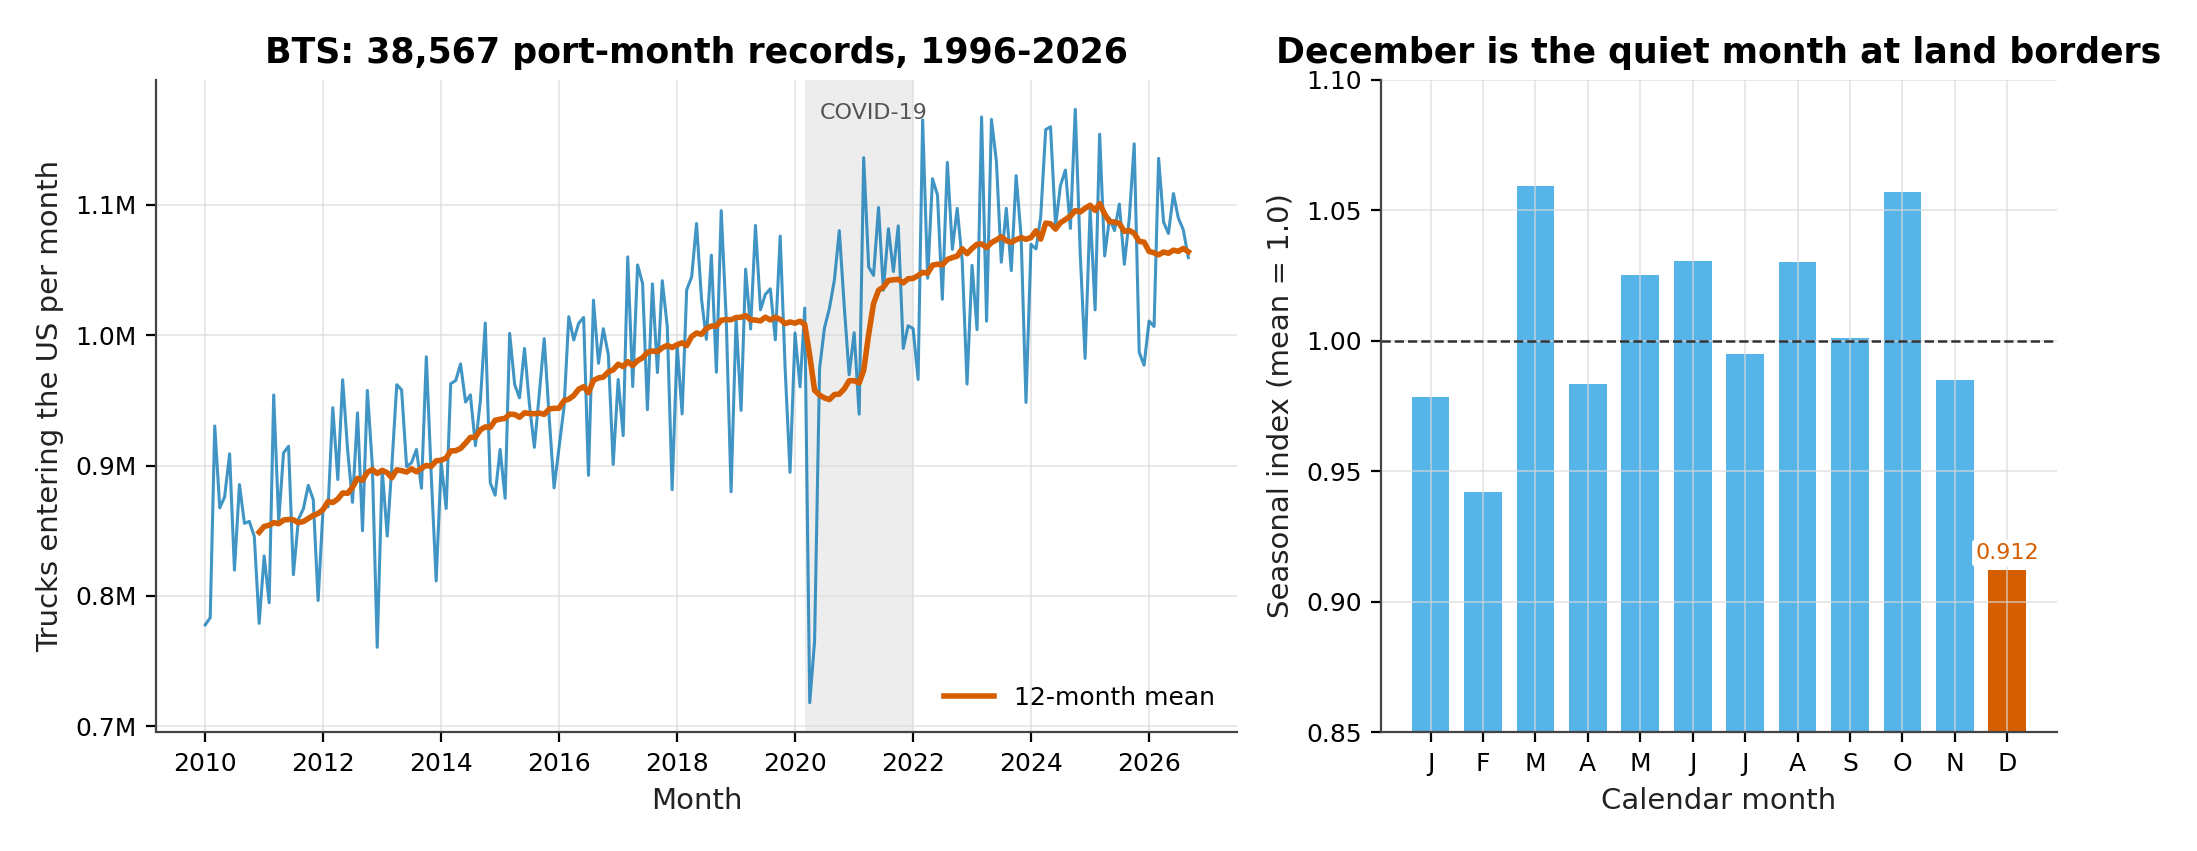

In [14]:
display(Image(filename=str(FIG / "fig15_bts_real_data.png"), width=760))

## 8. What the notebook shows

- Service is mode-specific: medians run from 3 days by air to 24 by sea, while
  on-time rates are highest for rail and lowest for air and road.
- Volume is strongly seasonal and flat between years; February 2025 is the one
  calendar shock that survives every cut.
- Two carriers sit far below a tight ten-carrier cluster, so the actionable
  comparison is two contracts, not a league table.
- Cost is a power law: a weight elasticity near 0.80 and a distance elasticity
  near 1.00 with mode fixed effects, which is also what the simulation planted.
- The residual outlier rule is fit for flagging, not for automatic deletion.